# Análise Financeira — Terra Signal

Nesta etapa, serão utilizados os dados preparados na camada Gold Financeira para analisar os impactos financeiros associados aos cancelamentos de clientes.

A análise será realizada por meio de indicadores e visualizações gráficas, buscando identificar os segmentos que concentram os maiores valores de receita mensal potencialmente perdida.

O objetivo é relacionar os resultados financeiros com os comportamentos identificados na análise exploratória, auxiliando na definição de estratégias de retenção de clientes e preservação de receita.

## Importação das bibliotecas e leitura dos dados

Serão importadas as bibliotecas necessárias para a análise financeira e a construção dos gráficos, juntamente com os arquivos gerados na camada Gold Financeira.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pasta_gold = Path("dados/gold")

df_indicadores = pd.read_csv(pasta_gold / "indicadores_financeiros.csv")
df_contratos = pd.read_csv(pasta_gold / "contratos_financeiro.csv")
df_internet = pd.read_csv(pasta_gold / "internet_financeiro.csv")
df_permanencia = pd.read_csv(pasta_gold / "permanencia_financeiro.csv")
df_contrato_internet = pd.read_csv(pasta_gold / "contrato_internet_financeiro.csv")

pasta_graficos = Path("graficos")
pasta_graficos.mkdir(parents=True, exist_ok=True)

In [3]:
df_indicadores

,Indicador,Valor,Unidade
0,Valor mensal total da carteira,364010.05,R$
1,Receita mensal dos clientes ativos,251767.15,R$
2,Receita mensal potencialmente perdida,112242.90,R$
3,Percentual de receita potencialmente perdida,30.84,%


## Impacto financeiro dos cancelamentos

Nesta etapa, será analisada a distribuição dos valores mensais associados aos clientes ativos e aos clientes que cancelaram os serviços.

O gráfico permitirá visualizar a participação da receita mensal potencialmente perdida em relação ao valor mensal total da carteira analisada.

O objetivo é compreender a dimensão financeira dos cancelamentos e a importância da retenção de clientes para a preservação da receita da empresa.

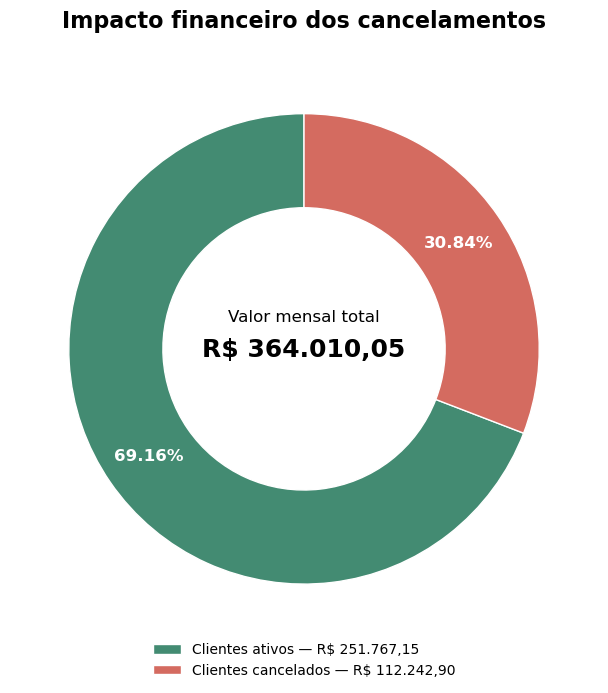

In [11]:
receita_ativa = df_indicadores.loc[1, "Valor"]
receita_perdida = df_indicadores.loc[2, "Valor"]
receita_total = receita_ativa + receita_perdida

valores = [receita_ativa, receita_perdida]

rotulos = [
    "Clientes ativos — R$ 251.767,15",
    "Clientes cancelados — R$ 112.242,90"
]

cores = ["#438b72", "#d46b60"]

plt.figure(figsize=(9, 7))

plt.pie(
    valores,
    colors=cores,
    autopct="%1.2f%%",
    startangle=90,
    pctdistance=0.80,
    wedgeprops={"width": 0.4, "edgecolor": "white"},
    textprops={"fontsize": 12, "color": "white", "weight": "bold"}
)

plt.text(
    0, 0.12,
    "Valor mensal total",
    ha="center",
    fontsize=12
)

plt.text(
    0, -0.03,
    "R$ 364.010,05",
    ha="center",
    fontsize=18,
    fontweight="bold"
)

plt.title(
    "Impacto financeiro dos cancelamentos",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.legend(
    rotulos,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    frameon=False
)

plt.tight_layout()
plt.savefig(pasta_graficos / "impacto_financeiro.png", dpi=300, bbox_inches="tight")
plt.show()

## Interpretação dos resultados

Os clientes ativos representam 69,16% do valor mensal total da carteira analisada, enquanto os clientes que cancelaram os serviços representam 30,84%.

Em valores financeiros, os cancelamentos estão associados a uma receita mensal potencialmente perdida de R$ 112.242,90.

Esse resultado demonstra a relevância financeira dos cancelamentos e reforça a importância de estratégias de retenção de clientes para a preservação da receita da empresa.

Como a base não apresenta as datas dos cancelamentos, esse valor não representa uma perda financeira efetivamente registrada em um determinado mês.

## Receita mensal potencialmente perdida por tipo de contrato

Nesta etapa, será analisado o impacto financeiro dos cancelamentos conforme o tipo de contrato dos clientes.

O objetivo é identificar quais modalidades de contrato concentram os maiores valores de receita mensal potencialmente perdida, relacionando os resultados financeiros com as taxas de cancelamento identificadas na análise exploratória.

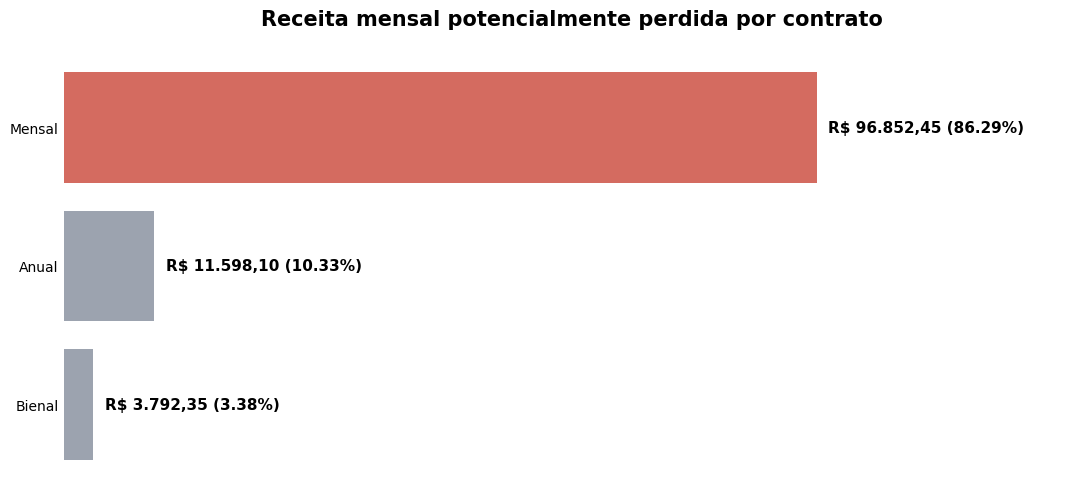

In [5]:
contratos = df_contratos["Tipo de contrato"].replace({
    "Month-to-month": "Mensal",
    "One year": "Anual",
    "Two year": "Bienal"
})

valores = df_contratos["Receita mensal potencialmente perdida"]
percentuais = df_contratos["Participação (%)"]

plt.figure(figsize=(11, 5))

barras = plt.barh(
    contratos,
    valores,
    color=["#d46b60", "#9ca3af", "#9ca3af"]
)

plt.gca().invert_yaxis()

for barra, valor, percentual in zip(barras, valores, percentuais):

    valor_formatado = f"{valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

    plt.text(
        valor + 1500,
        barra.get_y() + barra.get_height() / 2,
        f"R$ {valor_formatado} ({percentual:.2f}%)",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Receita mensal potencialmente perdida por contrato",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xlim(0, valores.max() * 1.35)
plt.xticks([])
plt.tick_params(axis="y", length=0)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.savefig(pasta_graficos / "financeiro_contratos.png", dpi=300, bbox_inches="tight")
plt.show()

## Interpretação dos resultados

Os contratos mensais concentram 86,29% da receita mensal potencialmente perdida, representando R$ 96.852,45.

Os contratos anuais representam 10,33%, enquanto os contratos bienais correspondem a apenas 3,38%.

Relacionando esses resultados com a análise exploratória, observa-se que os contratos mensais apresentam tanto a maior taxa de cancelamento quanto o maior impacto financeiro associado aos cancelamentos.

Esses resultados indicam que os clientes com contratos mensais devem receber maior atenção nas estratégias de retenção, incluindo a avaliação de incentivos para a migração para contratos de maior duração.

## Receita mensal potencialmente perdida por serviço de internet

Nesta etapa, será analisado o impacto financeiro dos cancelamentos conforme o serviço de internet contratado pelos clientes.

O objetivo é identificar quais serviços concentram os maiores valores de receita mensal potencialmente perdida, relacionando os resultados financeiros com as taxas de cancelamento identificadas na análise exploratória.

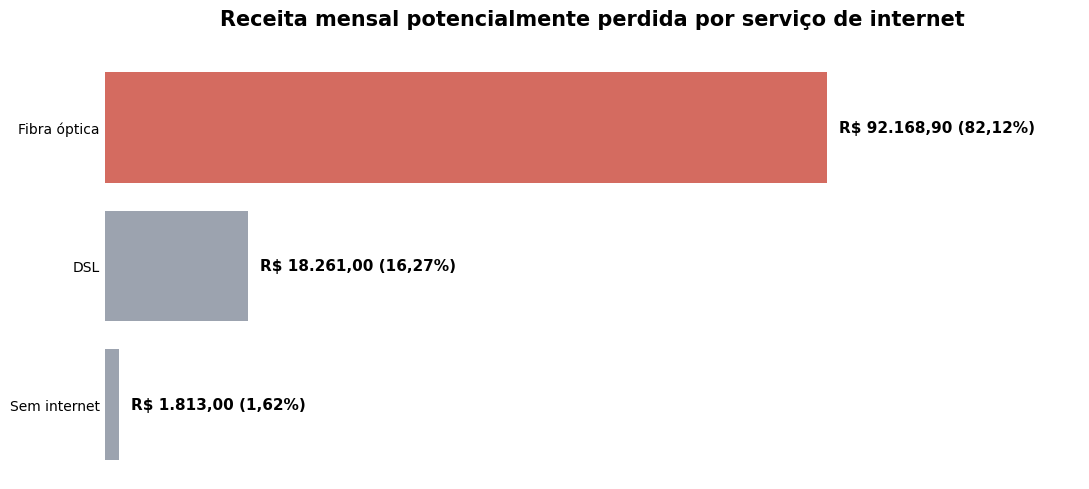

In [6]:
df_internet = df_internet.sort_values(
    "Receita mensal potencialmente perdida",
    ascending=False
)

servicos = df_internet["Serviço de internet"].replace({
    "Fiber optic": "Fibra óptica",
    "DSL": "DSL",
    "No": "Sem internet"
})

valores = df_internet["Receita mensal potencialmente perdida"]
percentuais = df_internet["Participação (%)"]

plt.figure(figsize=(11, 5))

barras = plt.barh(
    servicos,
    valores,
    color=["#d46b60", "#9ca3af", "#9ca3af"]
)

plt.gca().invert_yaxis()

for barra, valor, percentual in zip(barras, valores, percentuais):

    valor_formatado = f"{valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")

    plt.text(
        valor + 1500,
        barra.get_y() + barra.get_height() / 2,
        f"R$ {valor_formatado} ({percentual_formatado}%)",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Receita mensal potencialmente perdida por serviço de internet",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xlim(0, valores.max() * 1.35)
plt.xticks([])
plt.tick_params(axis="y", length=0)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.savefig(pasta_graficos / "financeiro_internet.png", dpi=300, bbox_inches="tight")
plt.show()

## Interpretação dos resultados

Os clientes de fibra óptica concentram 82,12% da receita mensal potencialmente perdida, representando R$ 92.168,90.

Os clientes com serviço DSL representam 16,27%, enquanto aqueles sem serviço de internet correspondem a apenas 1,62%.

Relacionando esses resultados com a análise exploratória, observa-se que a fibra óptica apresenta tanto a maior taxa de cancelamento quanto o maior impacto financeiro associado aos cancelamentos.

Esses resultados indicam a importância de investigar os motivos de insatisfação dos clientes de fibra óptica, considerando fatores como qualidade do serviço, atendimento e preços praticados.

## Receita mensal potencialmente perdida por tempo de permanência

Nesta etapa, será analisado o impacto financeiro dos cancelamentos conforme o tempo de permanência dos clientes na empresa.

O gráfico permitirá identificar quais faixas de permanência concentram os maiores valores de receita mensal potencialmente perdida, auxiliando na definição de estratégias de retenção.

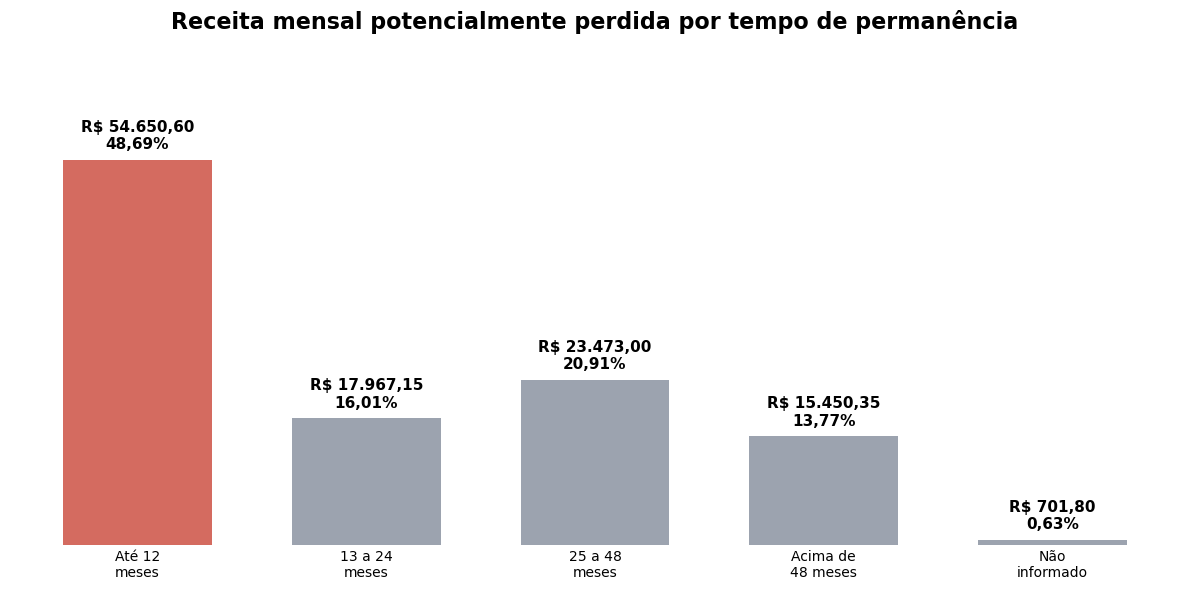

In [7]:
rotulos = [
    "Até 12\nmeses",
    "13 a 24\nmeses",
    "25 a 48\nmeses",
    "Acima de\n48 meses",
    "Não\ninformado"
]

valores = df_permanencia["Receita mensal potencialmente perdida"]
percentuais = df_permanencia["Participação (%)"]

cores = ["#D46B60", "#9CA3AF", "#9CA3AF", "#9CA3AF", "#9CA3AF"]

plt.figure(figsize=(12, 6))

plt.bar(rotulos, valores, color=cores, width=0.65)

for i in range(len(valores)):
    valor = f"{valores.iloc[i]:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    percentual = f"{percentuais.iloc[i]:.2f}".replace(".", ",")

    plt.text(
        i,
        valores.iloc[i] + 1500,
        f"R$ {valor}\n{percentual}%",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Receita mensal potencialmente perdida por tempo de permanência",
    fontsize=16,
    fontweight="bold",
    pad=25
)

plt.ylim(0, valores.max() * 1.25)
plt.yticks([])
plt.tick_params(axis="x", length=0)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.savefig(pasta_graficos / "financeiro_permanencia.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretação dos resultados

Os clientes com até 12 meses de permanência concentram o maior impacto financeiro associado aos cancelamentos, representando R$ 54.650,60, equivalente a 48,69% da receita mensal potencialmente perdida.

Somando os clientes com até 24 meses de permanência, esse percentual chega a 64,70%, totalizando R$ 72.617,75.

Esses resultados reforçam a importância de desenvolver estratégias de retenção principalmente durante os primeiros dois anos de relacionamento com a empresa, com maior atenção ao primeiro ano.

Os clientes sem tempo de permanência informado foram mantidos na análise, preservando a totalidade dos valores financeiros.

## Análise financeira cruzada por contrato e serviço de internet

Nesta etapa, será analisada a receita mensal potencialmente perdida considerando a combinação entre o tipo de contrato e o serviço de internet dos clientes que cancelaram.

O objetivo é identificar quais combinações concentram os maiores impactos financeiros associados aos cancelamentos, permitindo direcionar estratégias de retenção para grupos mais específicos de clientes.

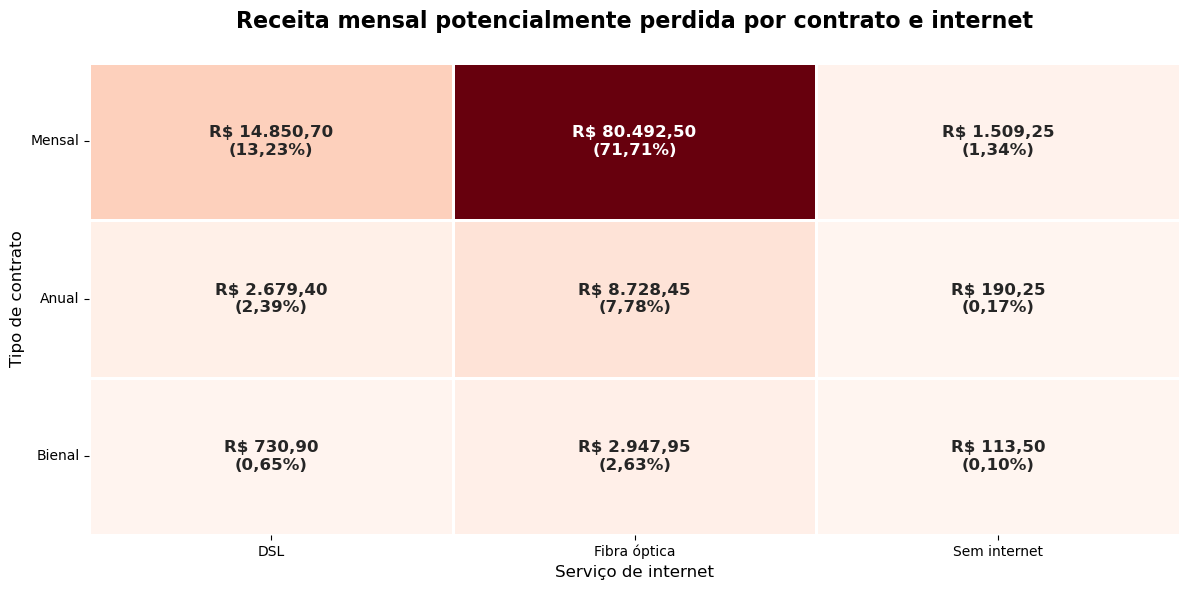

In [8]:
matriz_receita = df_contrato_internet.pivot(
    index="Tipo de contrato",
    columns="Serviço de internet",
    values="Receita mensal potencialmente perdida"
)

matriz_percentual = df_contrato_internet.pivot(
    index="Tipo de contrato",
    columns="Serviço de internet",
    values="Participação (%)"
)

matriz_receita.index = ["Mensal", "Anual", "Bienal"]
matriz_receita.columns = ["DSL", "Fibra óptica", "Sem internet"]

rotulos = matriz_receita.copy().astype(str)

for i in range(3):
    for j in range(3):
        valor = matriz_receita.iloc[i, j]
        percentual = matriz_percentual.iloc[i, j]

        valor_formatado = f"{valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
        percentual_formatado = f"{percentual:.2f}".replace(".", ",")

        rotulos.iloc[i, j] = f"R$ {valor_formatado}\n({percentual_formatado}%)"

plt.figure(figsize=(12, 6))

sns.heatmap(
    matriz_receita,
    annot=rotulos,
    fmt="",
    cmap="Reds",
    linewidths=2,
    linecolor="white",
    cbar=False,
    annot_kws={"size": 12, "weight": "bold"}
)

plt.title(
    "Receita mensal potencialmente perdida por contrato e internet",
    fontsize=16,
    fontweight="bold",
    pad=25
)

plt.xlabel("Serviço de internet", fontsize=12)
plt.ylabel("Tipo de contrato", fontsize=12)

plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(pasta_graficos / "financeiro_contrato_internet.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretação dos resultados

Os clientes com contrato mensal e serviço de fibra óptica concentram o maior impacto financeiro associado aos cancelamentos, totalizando R$ 80.492,50, equivalente a 71,71% da receita mensal potencialmente perdida.

Em seguida, destacam-se os clientes com contrato mensal e serviço DSL (13,23%) e os clientes com contrato anual e fibra óptica (7,78%).

O cruzamento das informações permite identificar que o impacto financeiro dos cancelamentos está fortemente concentrado em uma combinação específica de contrato e serviço de internet.

Esses resultados indicam que os clientes com contrato mensal e fibra óptica devem ser priorizados nas estratégias de retenção, buscando compreender os motivos dos cancelamentos e reduzir seus impactos financeiros.

## Consolidação dos resultados financeiros

Após as análises individuais e cruzadas, serão reunidos os principais resultados financeiros associados aos cancelamentos.

O objetivo é apresentar uma visão consolidada dos segmentos que concentram os maiores valores de receita mensal potencialmente perdida, facilitando a identificação das prioridades para as estratégias de retenção.

In [9]:
tabela_consolidada = pd.DataFrame({
    "Dimensão analisada": [
        "Tipo de contrato",
        "Serviço de internet",
        "Tempo de permanência",
        "Contrato e internet"
    ],
    "Segmento prioritário": [
        "Contrato mensal",
        "Fibra óptica",
        "Até 12 meses",
        "Contrato mensal e fibra óptica"
    ],
    "Receita mensal potencialmente perdida": [
        df_contratos["Receita mensal potencialmente perdida"].max(),
        df_internet["Receita mensal potencialmente perdida"].max(),
        df_permanencia["Receita mensal potencialmente perdida"].max(),
        df_contrato_internet["Receita mensal potencialmente perdida"].max()
    ],
    "Participação (%)": [
        df_contratos["Participação (%)"].max(),
        df_internet["Participação (%)"].max(),
        df_permanencia["Participação (%)"].max(),
        df_contrato_internet["Participação (%)"].max()
    ]
})

tabela_consolidada

,Dimensão analisada,Segmento prioritário,Receita mensal potencialmente perdida,Participação (%)
0,Tipo de contrato,Contrato mensal,96852.45,86.29
1,Serviço de internet,Fibra óptica,92168.90,82.12
2,Tempo de permanência,Até 12 meses,54650.60,48.69
3,Contrato e internet,Contrato mensal e fibra óptica,80492.50,71.71


### Interpretação dos resultados consolidados

A consolidação dos resultados demonstra que o impacto financeiro associado aos cancelamentos está concentrado principalmente nos clientes com contratos mensais, serviço de fibra óptica e menor tempo de permanência.

Os contratos mensais representam 86,29% da receita mensal potencialmente perdida, enquanto os clientes com fibra óptica representam 82,12%.

Em relação ao tempo de permanência, os clientes com até 12 meses concentram 48,69% do impacto financeiro associado aos cancelamentos.

A análise cruzada permite identificar um segmento ainda mais específico: os clientes com contrato mensal e fibra óptica, que representam R$ 80.492,50, equivalente a 71,71% da receita mensal potencialmente perdida.

É importante destacar que os valores apresentados não devem ser somados, pois um mesmo cliente pode estar presente em diferentes segmentos analisados.

Esses resultados servirão como base para a elaboração das recomendações estratégicas de retenção de clientes e preservação de receita.

## Recomendações estratégicas de retenção

Com base nos resultados das análises exploratória e financeira, foram identificados segmentos de clientes que devem receber maior atenção nas estratégias de retenção.

### Clientes com contratos mensais

- Avaliar a possibilidade de oferecer benefícios para a migração para contratos anuais ou bienais.
- Desenvolver ofertas de fidelização para clientes com contratos mensais.
- Investigar os principais motivos de cancelamento nesse segmento.

### Clientes com serviço de fibra óptica

- Avaliar a satisfação dos clientes em relação à qualidade do serviço prestado.
- Investigar possíveis problemas relacionados à estabilidade da conexão, ao atendimento e aos valores cobrados.
- Avaliar a adequação dos planos oferecidos às necessidades dos clientes.

### Clientes com até 12 meses de permanência

- Realizar um acompanhamento mais próximo durante o primeiro ano de relacionamento.
- Aplicar pesquisas de satisfação nos primeiros meses após a contratação.
- Identificar antecipadamente possíveis insatisfações e dificuldades na utilização dos serviços.

### Clientes com contrato mensal e fibra óptica

Esse segmento deve receber atenção especial, pois concentra 71,71% da receita mensal potencialmente perdida, representando R$ 80.492,50.

Recomenda-se desenvolver ações de retenção direcionadas a esse grupo, considerando suas características contratuais e os serviços utilizados.

### Considerações sobre as recomendações

As ações propostas foram elaboradas com base nos padrões identificados nas análises. Entretanto, os dados disponíveis não permitem determinar as causas efetivas dos cancelamentos.

Recomenda-se a realização de pesquisas complementares para compreender esses motivos e avaliar a efetividade das estratégias propostas.

## Exportação dos gráficos

Os gráficos desenvolvidos durante a análise financeira foram exportados em formato PNG e armazenados na pasta `graficos`.

As imagens poderão ser utilizadas na documentação e na apresentação final do projeto Terra Signal.

In [10]:
list(pasta_graficos.glob("*.png"))

[WindowsPath('graficos/financeiro_contratos.png'),
 WindowsPath('graficos/financeiro_contrato_internet.png'),
 WindowsPath('graficos/financeiro_internet.png'),
 WindowsPath('graficos/financeiro_permanencia.png'),
 WindowsPath('graficos/impacto_financeiro.png')]

## Conclusão da análise financeira

A análise financeira permitiu identificar a dimensão do impacto dos cancelamentos sobre a receita da Terra Signal.

Do valor mensal total de R$ 364.010,05 associado à carteira analisada, R$ 112.242,90 correspondem aos clientes que cancelaram os serviços, representando 30,84% do total.

As análises individuais e cruzadas permitiram identificar os segmentos que concentram os maiores impactos financeiros, com destaque para os clientes com contrato mensal e fibra óptica e para aqueles com menor tempo de permanência.

A partir desses resultados, foram propostas estratégias de retenção direcionadas aos segmentos prioritários, buscando contribuir para a redução dos cancelamentos e a preservação da receita.

Como limitação da análise, destaca-se a ausência das datas e dos motivos dos cancelamentos, impossibilitando a determinação das perdas financeiras efetivas em um período específico e das causas dos cancelamentos.

Os indicadores, as tabelas e os gráficos desenvolvidos servirão como base para a documentação, a apresentação final do projeto e o apoio à tomada de decisão.